In [26]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from functools import partial
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from cdrmip_extremes import (
    amoc, processing, utils, io_disk, stats
)
from cdrmip_extremes.utils import _map_leaves, reduce_member_tree
from cdrmip_extremes.configs import DATA_DIR, PROC_DIR, CDR_MODELS, cdr_colour_dict as colour_dict, FIG_DIR

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [10]:
gsat = utils.reduce_member_tree(io_disk.load_tree(PROC_DIR, 'gsat', 'CDRMIP', model_order=CDR_MODELS))
gsat_rolling = utils.reduce_member_tree(io_disk.load_tree(PROC_DIR, 'gsat_rolling', 'CDRMIP', model_order=CDR_MODELS))
crossing_years = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'crossing_years', 'CDRMIP', as_dataarray=True,model_order=CDR_MODELS)
)
gwl_matching_years = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'gwl_matching_years', 'CDRMIP', as_dataarray=True,model_order=CDR_MODELS),
    drop_coords=['gwl']
)

In [11]:
amoc_data = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'amoc', 'CDRMIP', model_order=CDR_MODELS, category='anomaly')
)
pi_amoc = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'amoc', 'CDRMIP', model_order=CDR_MODELS)
)

In [12]:
peak_warming = io_disk.load_peak_warming('CDRMIP',PROC_DIR)

### Identify Changes at 1.5ºC Warming ###

In [13]:
expt = '1pctCO2-cdr'

def amoc_summary(model):
    series = stats._rolling_mean(amoc_data[model][expt]['amoc'], 21, time_dim='year').load()
    pi_annual = pi_amoc[model]['piControl']['amoc'].groupby('time.year').mean()
    cy = crossing_years[model][expt].sel(gwl=1.5)
    up, down = (int(cy.sel(branch=b)) for b in ('ramp_up', 'ramp_down'))
    peak_year = np.median([d['peak_year'] for d in peak_warming[model][expt].values()])
    return dict(series=series, std=float(pi_annual.std()), up=up, down=down, peak_year=peak_year,
                up_val=float(series.sel(year=up)), down_val=float(series.sel(year=down)))

summary = {m: amoc_summary(m) for m in amoc_data}
order = sorted(summary, key=lambda m: summary[m]['down_val'] - summary[m]['up_val'])

for m in order:
    s = summary[m]
    print(f"{m}: ΔAMOC = {s['down_val'] - s['up_val']:.2f} Sv "
          f"(1.5°C up {s['up']}, down {s['down']}), piControl σ = {s['std']:.2f} Sv")

CESM2: ΔAMOC = -4.46 Sv (1.5°C up 51, down 266), piControl σ = 0.82 Sv
CNRM-ESM2-1: ΔAMOC = -3.35 Sv (1.5°C up 59, down 271), piControl σ = 2.01 Sv
MIROC-ES2L: ΔAMOC = -2.31 Sv (1.5°C up 67, down 236), piControl σ = 1.07 Sv
NorESM2-LM: ΔAMOC = -1.17 Sv (1.5°C up 71, down 214), piControl σ = 0.78 Sv
UKESM1-0-LL: ΔAMOC = 1.25 Sv (1.5°C up 38, down 332), piControl σ = 0.95 Sv
GFDL-ESM4: ΔAMOC = 1.88 Sv (1.5°C up 68, down 243), piControl σ = 1.17 Sv
ACCESS-ESM1-5: ΔAMOC = 3.48 Sv (1.5°C up 59, down 262), piControl σ = 0.95 Sv
CanESM5: ΔAMOC = 3.53 Sv (1.5°C up 45, down 290), piControl σ = 0.83 Sv


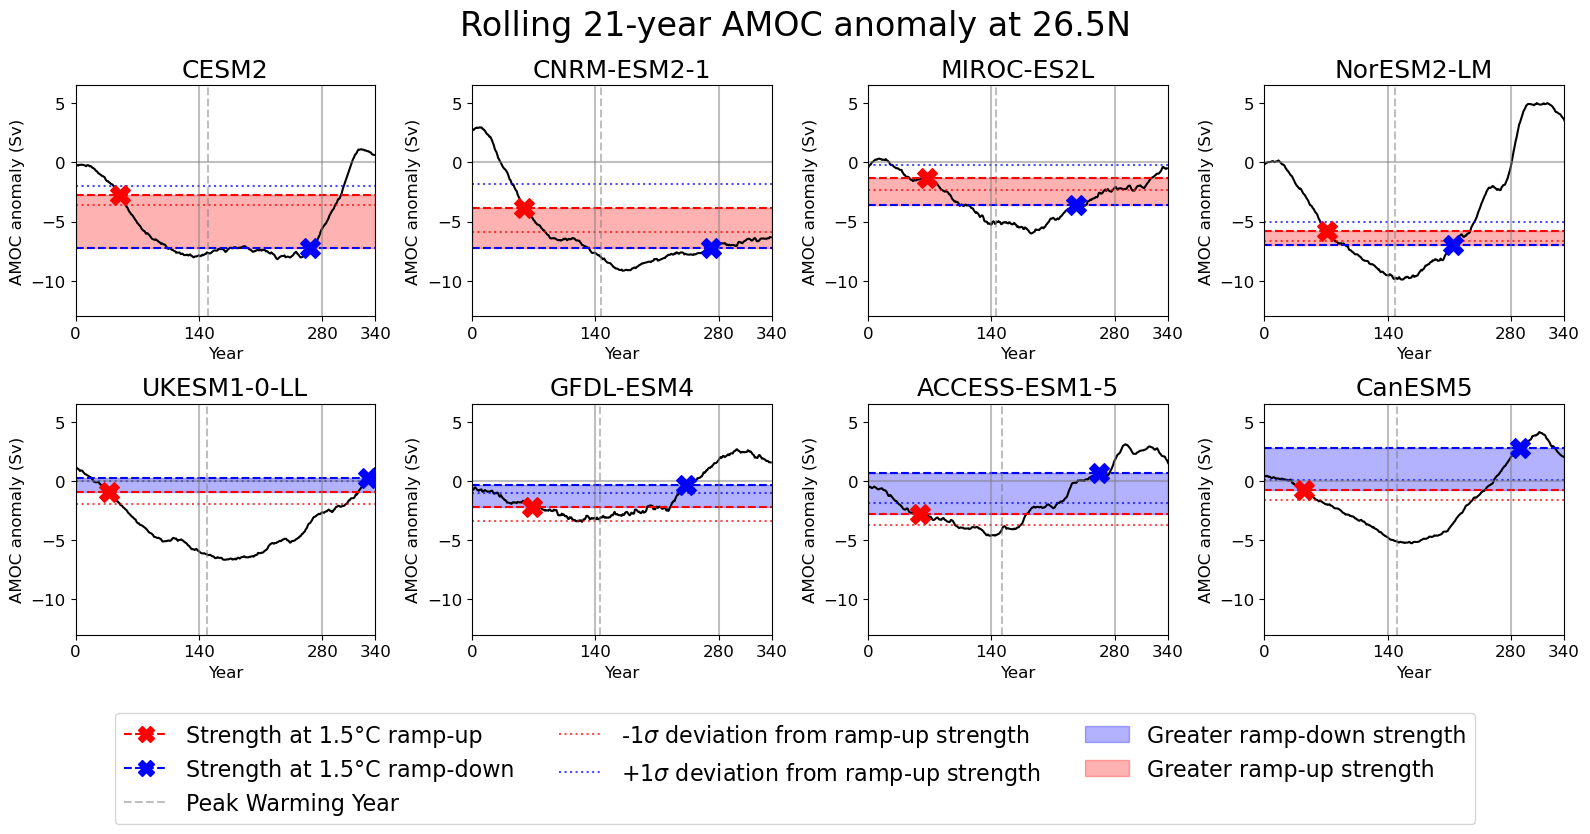

In [14]:
plt.rcParams.update({'axes.labelsize': 12, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, m in zip(axes.flat, order):
    s = summary[m]
    s['series'].plot(ax=ax, color='black')

    ax.scatter(s['up'], s['up_val'], marker='X', s=200, color='red', zorder=3,
               label='Strength at 1.5°C ramp-up')
    ax.scatter(s['down'], s['down_val'], marker='X', s=200, color='blue', zorder=3,
               label='Strength at 1.5°C ramp-down')
    ax.axhline(s['up_val'], ls='--', color='red')
    ax.axhline(s['down_val'], ls='--', color='blue')
    ax.axhline(s['up_val'] - s['std'], ls=':', color='red', alpha=0.7,
               label=r'-1$\sigma$ deviation from ramp-up strength')
    ax.axhline(s['up_val'] + s['std'], ls=':', color='blue', alpha=0.7,
               label=r'+1$\sigma$ deviation from ramp-up strength')
    ax.axhspan(*sorted((s['up_val'], s['down_val'])), alpha=0.3,
               color='blue' if s['down_val'] > s['up_val'] else 'red')

    ax.axvline(s['peak_year'], ls='--', color='grey', alpha=0.5, label='Peak Warming Year')
    for x in (140, 280):
        ax.axvline(x, color='grey', alpha=0.5)
    ax.axhline(0, ls='-', color='grey', alpha=0.5)

    ax.set_title(m, fontsize=18)
    ax.set(xlabel='Year', ylabel='AMOC anomaly (Sv)', xlim=(0, 340), ylim=(-13, 6.5),
           xticks=[0, 140, 280, 340])

for ax in axes.flat[len(order):]:   # hide unused panels
    ax.remove()

branch = lambda c, lab: Line2D([], [], color=c, ls='--', marker='X', markersize=12, label=lab)

handles = [
    branch('red', 'Strength at 1.5°C ramp-up'),
    branch('blue', 'Strength at 1.5°C ramp-down'),
    Line2D([], [], color='grey', ls='--', alpha=0.5, label='Peak Warming Year'),
    Line2D([], [], color='red', ls=':', alpha=0.7, label=r'-1$\sigma$ deviation from ramp-up strength'),
    Line2D([], [], color='blue', ls=':', alpha=0.7, label=r'+1$\sigma$ deviation from ramp-up strength'),
    Patch(color='blue', alpha=0.3, label='Greater ramp-down strength'),
    Patch(color='red', alpha=0.3, label='Greater ramp-up strength'),
]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=16)
fig.suptitle('Rolling 21-year AMOC anomaly at 26.5N', fontsize=24)
fig.tight_layout()

In [15]:
fig.savefig(
    FIG_DIR / "main" / "figure_5.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

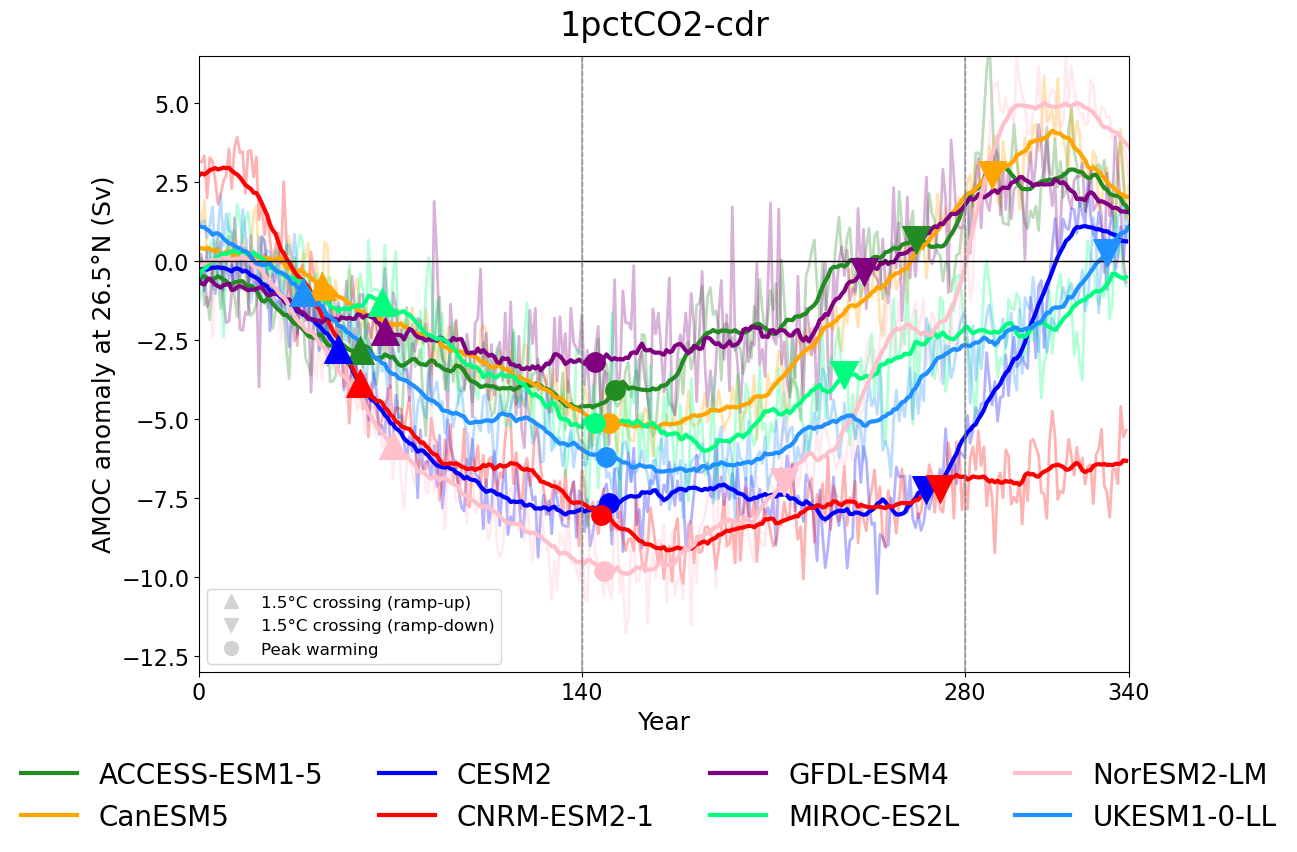

In [50]:
from cdrmip_extremes.plotting.timeseries import plot_gsat_timeseries 
amoc_rolling = _map_leaves(amoc_data, lambda ds: stats._rolling_mean(ds, 21, 'year'))

models = sorted(amoc_data)

fig, ax = plt.subplots(figsize=(12, 8))
plot_gsat_timeseries(
    amoc_rolling, colour_dict,
    raw_tree=amoc_data, raw_alpha=0.3,
    varname='amoc', title='1pctCO2-cdr',
    ylabel='AMOC anomaly at 26.5°N (Sv)', xlabel='Year',
    xlim=(0, 340), ylim=(-13, 6.5), legend_loc=None,
    fig=fig, ax=ax,
)
for m, s in summary.items():
    kw = dict(color=colour_dict[m], s=400, linewidth=0.8, zorder=4)
    ax.scatter(s['up'], s['up_val'], marker='^', **kw)
    ax.scatter(s['down'], s['down_val'], marker='v', **kw)
    ax.scatter(s['peak_year'], float(s['series'].sel(year=s['peak_year'], method='nearest')),
               marker='o', s=200,color=colour_dict[m],zorder=4,linewidth=0.8)


marker_key = [
    Line2D([], [], ls='', marker=mk, markersize=10, color='lightgrey', label=lab)
    for mk, lab in [('^', '1.5°C crossing (ramp-up)'),
                    ('v', '1.5°C crossing (ramp-down)'),
                    ('o', 'Peak warming')]
]
ax.legend(handles=marker_key, loc='lower left', fontsize=12)
for x in (140, 280):   # peak CO2, return to PI CO2
    ax.axvline(x, color='grey', alpha=0.5)
ax.set_xticks([0, 140, 280, 340])

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=20,
           frameon=False, bbox_to_anchor=(0.5, -0.12))

## AMOC Changes at end of simulation

In [22]:
int(gwl_matching_years['ACCESS-ESM1-5'][expt].sel(branch='ramp_up').values)

30

In [25]:
def amoc_final(model):
    series = stats._rolling_mean(amoc_data[model][expt]['amoc'], 21, time_dim='year').load()
    gmy = gwl_matching_years[model][expt]
    up, down= (int(gmy.sel(branch=b).values) for b in ('ramp_up', 'ramp_down'))
    amoc_up = series.sel(year=up).values
    amoc_down = series.sel(year=down).values
    return dict(up_val=amoc_up, down_val=amoc_down, up=up, down=down)

final = {m: amoc_final(m) for m in amoc_data}
final_order = sorted(final, key=lambda m: final[m]['down_val'] - summary[m]['up_val'])

for m in final_order:
    s = final[m]
    print(f"{m}: ΔAMOC = {s['down_val'] - s['up_val']:.2f} Sv "
          f"(1.5°C up {s['up']}, down {s['down']})")

CNRM-ESM2-1: ΔAMOC = -6.69 Sv (1.5°C up 31, down 330)
MIROC-ES2L: ΔAMOC = -1.17 Sv (1.5°C up 17, down 330)
UKESM1-0-LL: ΔAMOC = 1.10 Sv (1.5°C up 39, down 330)
CanESM5: ΔAMOC = 3.01 Sv (1.5°C up 34, down 330)
CESM2: ΔAMOC = 3.13 Sv (1.5°C up 45, down 330)
GFDL-ESM4: ΔAMOC = 3.23 Sv (1.5°C up 34, down 330)
ACCESS-ESM1-5: ΔAMOC = 4.04 Sv (1.5°C up 30, down 330)
NorESM2-LM: ΔAMOC = 5.41 Sv (1.5°C up 30, down 330)
